1. Importation des bibliothèques requises

In [1]:
!pip install torchmetrics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 13.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [torchmetrics]


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


import torch
from torch import optim
from torch import nn
from torch.utils.data import DataLoader
from tqdm import tqdm

# !pip install torchvision
import torchvision

import torch.nn.functional as F
import torchvision.datasets as datasets
import torchvision.transforms as transforms

# !pip install torchmetrics
import torchmetrics

2. Chargement et prétraitement de l'ensemble de données

In [3]:
batch_size = 60

train_dataset = datasets.MNIST(root="dataset/", download=True, train=True, transform=transforms.ToTensor())

train_loader = DataLoader(dataset=train_dataset, batch_size=batch_size, shuffle=True)

test_dataset = datasets.MNIST(root="dataset/", download=True, train=False, transform=transforms.ToTensor())

test_loader = DataLoader(dataset=test_dataset, batch_size=batch_size, shuffle=True)

100%|██████████| 9.91M/9.91M [00:00<00:00, 18.0MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 513kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.61MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 11.7MB/s]


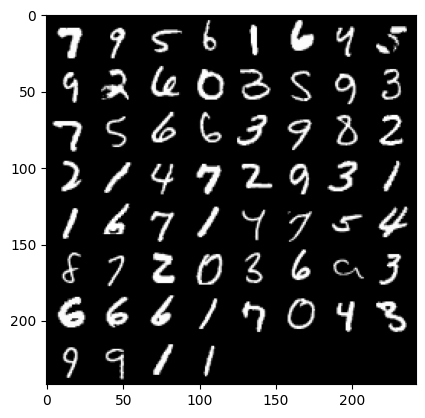

In [4]:
def imshow(img):
   npimg = img.numpy()
   plt.imshow(np.transpose(npimg, (1, 2, 0)))
   plt.show()

# get some random training images
dataiter = iter(train_loader)
images, labels = next(dataiter)
labels
# show images
imshow(torchvision.utils.make_grid(images))


3. Définition de l'architecture du CNN

In [5]:
class CNN(nn.Module):
   def __init__(self, in_channels, num_classes):

       """
       Building blocks of convolutional neural network.

       Parameters:
           * in_channels: Number of channels in the input image (for grayscale images, 1)
           * num_classes: Number of classes to predict. In our problem, 10 (i.e digits from  0 to 9).
       """
       super(CNN, self).__init__()

       # 1st convolutional layer
       self.conv1 = nn.Conv2d(in_channels=in_channels, out_channels=8, kernel_size=3, padding=1)
       # Max pooling layer
       self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
       # 2nd convolutional layer
       self.conv2 = nn.Conv2d(in_channels=8, out_channels=16, kernel_size=3, padding=1)
       # Fully connected layer
       self.fc1 = nn.Linear(16 * 7 * 7, num_classes)

   def forward(self, x):
       """
       Define the forward pass of the neural network.

       Parameters:
           x: Input tensor.

       Returns:
           torch.Tensor
               The output tensor after passing through the network.
       """
       x = F.relu(self.conv1(x))  # Apply first convolution and ReLU activation
       x = self.pool(x)           # Apply max pooling
       x = F.relu(self.conv2(x))  # Apply second convolution and ReLU activation
       x = self.pool(x)           # Apply max pooling
       x = x.reshape(x.shape[0], -1)  # Flatten the tensor
       x = self.fc1(x)            # Apply fully connected layer
       return x
       x = x.reshape(x.shape[0], -1)  # Flatten the tensor
       x = self.fc1(x)            # Apply fully connected layer
       return x

In [6]:
device = "cuda" if torch.cuda.is_available() else "cpu"

model = CNN(in_channels=1, num_classes=10).to(device)
print(model)

CNN(
  (conv1): Conv2d(1, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (fc1): Linear(in_features=784, out_features=10, bias=True)
)


4. Formation du modèle CNN

In [7]:
# Define the loss function
criterion = nn.CrossEntropyLoss()

# Define the optimizer
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [8]:
num_epochs=10
for epoch in range(num_epochs):
 # Iterate over training batches
   print(f"Epoch [{epoch + 1}/{num_epochs}]")

   for batch_index, (data, targets) in enumerate(tqdm(train_loader)):
       data = data.to(device)
       targets = targets.to(device)
       scores = model(data)
       loss = criterion(scores, targets)
       optimizer.zero_grad()
       loss.backward()
       optimizer.step()

Epoch [1/10]


100%|██████████| 1000/1000 [00:11<00:00, 89.16it/s]


Epoch [2/10]


100%|██████████| 1000/1000 [00:08<00:00, 113.50it/s]


Epoch [3/10]


100%|██████████| 1000/1000 [00:08<00:00, 123.13it/s]


... (10 outputs left out)

Epoch [9/10]


100%|██████████| 1000/1000 [00:08<00:00, 119.86it/s]


Epoch [10/10]


100%|██████████| 1000/1000 [00:08<00:00, 113.54it/s]


5. Évaluation du modèle

In [11]:
import time
from torchmetrics.classification import Accuracy, F1Score

# 1. Initialisation des métriques torchmetrics pour le test
test_acc_metric = Accuracy(task="multiclass", num_classes=10).to(device)
test_f1_metric = F1Score(task="multiclass", num_classes=10, average='macro').to(device)

# Chronomètre pour le temps d'évaluation / test (ou tu peux chronométrer l'ensemble)
start_eval_time = time.time()

# Passage du modèle en mode évaluation
model.eval()
test_loss = 0.0
test_acc_metric.reset()
test_f1_metric.reset()

with torch.no_grad():
    for data, targets in test_loader:
        data = data.to(device)
        targets = targets.to(device)

        # Forward pass
        scores = model(data)
        loss = criterion(scores, targets)

        # Accumulation de la loss
        test_loss += loss.item() * data.size(0)

        # Récupération des prédictions (classe avec la plus haute probabilité)
        _, preds = torch.max(scores, 1)

        # Mise à jour des métriques
        test_acc_metric.update(preds, targets)
        test_f1_metric.update(preds, targets)

# Calcul final des métriques sur tout le dataset de test
final_test_loss = test_loss / len(test_loader.dataset)
final_test_acc = test_acc_metric.compute()
final_test_f1 = test_f1_metric.compute()

end_eval_time = time.time()
evaluation_time = end_eval_time - start_eval_time

# Affichage des résultats finaux demandés pour le comparatif
print("\n--- Résultats d'Évaluation (Test) ---")
print(f"Loss (Test)     : {final_test_loss:.4f}")
print(f"Accuracy (Test) : {final_test_acc.item():.4f}")
print(f"F1-Score (Test) : {final_test_f1.item():.4f}")
print(f"Temps d'éval    : {evaluation_time:.2f} secondes")


--- Résultats d'Évaluation (Test) ---
Loss (Test)     : 0.0401
Accuracy (Test) : 0.9861
F1-Score (Test) : 0.9860
Temps d'éval    : 1.51 secondes


6. Déployer le modèle CNN

In [12]:
# Save the model
torch.save(model.state_dict(), 'MulticlassCNN.pth')

# Create a new model
loaded_model = CNN(in_channels=1, num_classes=10)

# Load the saved model
loaded_model.load_state_dict(torch.load('MulticlassCNN.pth'))
print(loaded_model)

CNN(
  (conv1): Conv2d(1, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (fc1): Linear(in_features=784, out_features=10, bias=True)
)
